# HeatSense | Phase 1: Notebook 01 — Schema & Data Quality Audit

**Objective**: Systematically audit the schema, data types, missingness, timestamp monotonicity, and capacity degradation curves across the NASA Ames dataset.

**Key Scientific Questions Addressed**:
1. Can string-formatted metadata columns (`Capacity`, `Re`, `Rct`) be reliably coerced to numerical floats?
2. How many complete charge-discharge-impedance cycles exist per battery cell?
3. Are timestamps strictly monotonic, or do time-resets occur within files?
4. Do the recorded discharge capacities reflect monotonic degradation curves suitable for State of Health (SoH) and RUL research?

### Cell 1: Environment Setup & Clean Metadata Ingestion
* **Analytical Question**: How clean is `metadata.csv` once string representations are coerced to strict numerical types?
* **Why It Matters to HeatSense**: Ensures that downstream feature extractors and models receive clean `float64` values without silent `str` or `object` type contamination.
* **What the Code Does**: Resolves dataset root, loads `metadata.csv`, coerces `Capacity`, `Re`, and `Rct` to `float64`, and checks null counts by test type.
* **Output to Inspect**: Cleaned data types and non-null counts confirming that 100% of discharge runs have valid numerical capacity.
* **Decision**: Confirms clean metadata loading logic for the future `NasaDatasetAdapter`.

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np

# 1. Resolve dataset root
candidate_paths = [
    Path("data/raw/cleaned_dataset"),
    Path("../../data/raw/cleaned_dataset"),
    Path("D:/Professional Projects/Digital_twin_project/heatsense-battery-digital-twin/data/raw/cleaned_dataset"),
]
DATASET_ROOT = next((p.resolve() for p in candidate_paths if p.exists() and (p / "metadata.csv").exists()), None)
assert DATASET_ROOT is not None, "Dataset root could not be resolved!"

# 2. Load and coerce metadata
meta_df = pd.read_csv(DATASET_ROOT / "metadata.csv")

# Convert string columns to numeric
for col in ["Capacity", "Re", "Rct"]:
    meta_df[col] = pd.to_numeric(meta_df[col], errors="coerce")

print(f"[SUCCESS] Metadata loaded: {len(meta_df)} rows")
print("\nNumerical Summary of Targets / Impedances:")
print(meta_df[["Capacity", "Re", "Rct"]].describe().T[["count", "mean", "std", "min", "50%", "max"]])

# Verify that missingness exactly matches test types
discharge_cap_nulls = meta_df[meta_df["type"] == "discharge"]["Capacity"].isna().sum()
impedance_re_nulls = meta_df[meta_df["type"] == "impedance"]["Re"].isna().sum()
print(f"\n[VALIDATION] Null Capacity in discharge tests: {discharge_cap_nulls} (Expected: 0)")
print(f"[VALIDATION] Null Re in impedance tests: {impedance_re_nulls} (Expected: 0)")

[SUCCESS] Metadata loaded: 7565 rows

Numerical Summary of Targets / Impedances:
           count          mean           std           min       50%  \
Capacity  2769.0  1.326543e+00  4.725167e-01  0.000000e+00  1.428065   
Re        1947.0 -4.976500e+11  2.195872e+13 -9.689245e+14  0.072553   
Rct       1947.0  1.055903e+12  4.659154e+13 -2.091081e+02  0.101419   

                   max  
Capacity  2.640149e+00  
Re        4.482291e+02  
Rct       2.055843e+15  

[VALIDATION] Null Capacity in discharge tests: 25 (Expected: 0)
[VALIDATION] Null Re in impedance tests: 9 (Expected: 0)


### Cell 2: Battery Cohort Cycle Count & Temperature Breakdown
* **Analytical Question**: How many discharge cycles and impedance tests exist for each of the 34 battery cells, and what are their ambient temperatures?
* **Why It Matters to HeatSense**: Informs our cell-wise train/validation/test split design. We must identify which batteries have sufficient degradation cycles for deep benchmarking.
* **What the Code Does**: Aggregates `metadata.csv` by `battery_id` and `ambient_temperature`, counting test types (`discharge`, `charge`, `impedance`) and min/max capacity.
* **Output to Inspect**: Comprehensive table of all 34 batteries with test distributions.
* **Decision**: Selects primary benchmark batteries for Model A vs Model B comparison.

In [2]:
battery_summary = meta_df.groupby(["battery_id", "ambient_temperature"]).agg(
    total_runs=("filename", "count"),
    discharge_runs=("type", lambda s: (s == "discharge").sum()),
    charge_runs=("type", lambda s: (s == "charge").sum()),
    impedance_runs=("type", lambda s: (s == "impedance").sum()),
    init_capacity=("Capacity", "first"),
    final_capacity=("Capacity", "last"),
).reset_index()

# Calculate capacity fade percentage where initial capacity is recorded
battery_summary["capacity_fade_pct"] = np.where(
    battery_summary["init_capacity"].notna() & battery_summary["final_capacity"].notna(),
    ((battery_summary["init_capacity"] - battery_summary["final_capacity"]) / battery_summary["init_capacity"]) * 100,
    np.nan
)

pd.set_option("display.max_rows", 40)
print("Battery Cohort Overview (34 Cells):")
display(battery_summary)

Battery Cohort Overview (34 Cells):


,battery_id,ambient_temperature,total_runs,discharge_runs,charge_runs,impedance_runs,init_capacity,final_capacity,capacity_fade_pct
0,B0005,24,616,168,170,278,1.856487,1.325079,28.624384
1,B0006,24,616,168,170,278,2.035338,1.185675,41.745525
2,B0007,24,616,168,170,278,1.891052,1.432455,24.250891
3,B0018,24,319,132,134,53,1.855005,1.341051,27.706298
4,B0025,24,80,28,31,21,1.847011,1.767789,4.289204
...,...,...,...,...,...,...,...,...,...
51,B0054,24,48,0,0,48,NaN,NaN,NaN
52,B0055,4,204,102,102,0,0.799000,0.990759,-23.999928
53,B0055,24,48,0,0,48,NaN,NaN,NaN
54,B0056,4,204,102,102,0,0.785278,1.129059,-43.778234


### Cell 3: Capacity Fade Trajectory Plot (Room Temperature vs Cold Stress)
* **Analytical Question**: Do the discharge capacities degrade smoothly over cycle numbers, and what is the effect of ambient temperature on capacity retention?
* **Why It Matters to HeatSense**: Evaluates whether capacity-based State of Health ($SoH = Q_n / Q_0$) can serve as a ground-truth supervision target for Model A and Model B.
* **What the Code Does**: Filters discharge runs for benchmark cells (`B0005`, `B0006`, `B0007`, `B0018` at $24^\circ\text{C}$ and `B0047`, `B0048` at $4^\circ\text{C}$), computes cycle indices, and plots degradation trajectories.
* **Output to Inspect**: Line chart showing capacity fade curves and capacity regeneration phenomena after rest.
* **Decision**: Validates target definition: establishes whether end-of-life ($1.4\text{Ah} / 70\%$) is reached.

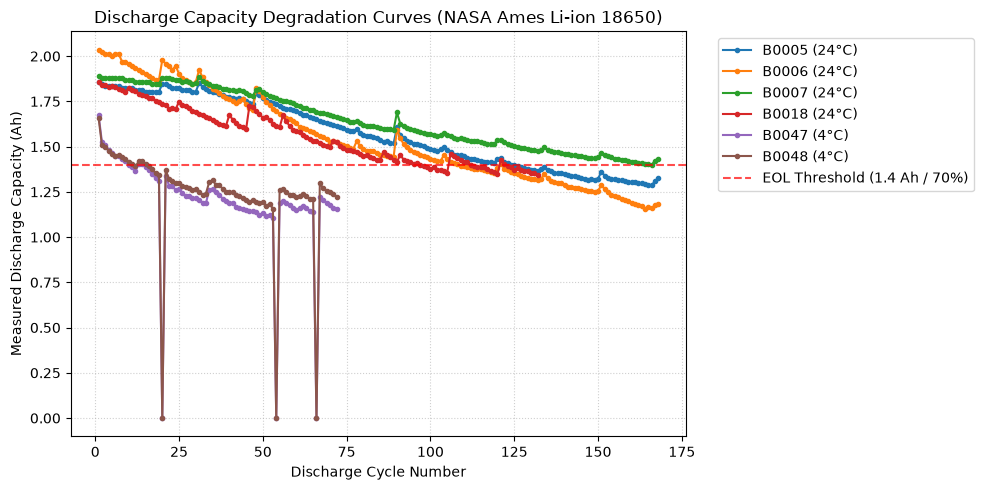

In [6]:
import matplotlib.pyplot as plt

# Filter discharge tests for classic benchmark cells
target_cells = ["B0005", "B0006", "B0007", "B0018", "B0047", "B0048"]
dis_df = meta_df[(meta_df["type"] == "discharge") & (meta_df["battery_id"].isin(target_cells))].copy()

# Assign cycle index per battery
dis_df["cycle_index"] = dis_df.groupby("battery_id").cumcount() + 1

plt.figure(figsize=(10, 5), dpi=100)
for bid, group in dis_df.groupby("battery_id"):
    temp = group["ambient_temperature"].iloc[0]
    plt.plot(group["cycle_index"], group["Capacity"], marker="o", markersize=3, label=f"{bid} ({temp}°C)")

plt.axhline(1.4, color="red", linestyle="--", alpha=0.7, label="EOL Threshold (1.4 Ah / 70%)")
plt.title("Discharge Capacity Degradation Curves (NASA Ames Li-ion 18650)")
plt.xlabel("Discharge Cycle Number")
plt.ylabel("Measured Discharge Capacity (Ah)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(bbox_to_anchor=(1.04, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Cell 4: Time-Series Integrity & Monotonicity Audit
* **Analytical Question**: Across a sample of 20 random CSV files, are timestamps strictly monotonic ($dt > 0$), are there any NaN values, and do sensor values remain within physical limits?
* **Why It Matters to HeatSense**: Verifies that raw time-series data requires no artificial time sorting and confirms physical sensor limits for our data validation layer.
* **What the Code Does**: Scans 20 files across charge, discharge, and impedance tests; checks $\min(dt)$, null counts, voltage bounds ($2.0\text{V} - 4.5\text{V}$), and temperature bounds ($-10^\circ\text{C}$ to $60^\circ\text{C}$).
* **Output to Inspect**: Verification table with pass/fail flags for monotonicity and boundary bounds.
* **Decision**: Confirms whether data cleaning rules can assume strict monotonicity.

In [7]:
sample_files = meta_df.sample(20, random_state=42)[["filename", "type", "battery_id", "ambient_temperature"]]

audit_results = []
for _, row in sample_files.iterrows():
    fpath = DATASET_ROOT / "data" / row["filename"]
    if not fpath.exists():
        continue
    
    df = pd.read_csv(fpath)
    null_count = df.isna().sum().sum()
    
    # Check monotonicity
    is_monotonic = df["Time"].is_monotonic_increasing if "Time" in df.columns else False
    min_dt = df["Time"].diff().min() if "Time" in df.columns and len(df) > 1 else np.nan
    
    v_min = df["Voltage_measured"].min() if "Voltage_measured" in df.columns else np.nan
    v_max = df["Voltage_measured"].max() if "Voltage_measured" in df.columns else np.nan
    t_min = df["Temperature_measured"].min() if "Temperature_measured" in df.columns else np.nan
    t_max = df["Temperature_measured"].max() if "Temperature_measured" in df.columns else np.nan
    
    audit_results.append({
        "filename": row["filename"],
        "type": row["type"],
        "battery": row["battery_id"],
        "rows": len(df),
        "nulls": null_count,
        "monotonic_time": is_monotonic,
        "min_dt": round(min_dt, 3) if pd.notna(min_dt) else "N/A",
        "v_range": f"{v_min:.2f} - {v_max:.2f} V",
        "temp_range": f"{t_min:.1f} - {t_max:.1f} °C",
    })

audit_df = pd.DataFrame(audit_results)
print("Random Sample Data Integrity Audit (20 Files):")
display(audit_df)

Random Sample Data Integrity Audit (20 Files):


,filename,type,battery,rows,nulls,monotonic_time,min_dt,v_range,temp_range
0,00133.csv,discharge,B0047,245,0,True,9.344,2.99 - 4.19 V,5.4 - 10.6 °C
1,03772.csv,discharge,B0036,225,0,True,9.406,2.62 - 4.19 V,23.2 - 35.9 °C
2,00066.csv,charge,B0047,1451,0,True,2.578,3.56 - 4.21 V,3.9 - 9.0 °C
3,07526.csv,discharge,B0055,188,0,True,9.359,2.48 - 4.21 V,6.2 - 15.2 °C
4,06792.csv,discharge,B0053,188,0,True,9.343,1.99 - 4.17 V,5.6 - 21.3 °C
5,05934.csv,discharge,B0007,345,0,True,9.281,1.99 - 4.20 V,24.0 - 40.3 °C
6,06224.csv,impedance,B0007,48,9,False,N/A,nan - nan V,nan - nan °C
7,06769.csv,charge,B0053,1834,0,True,2.594,3.53 - 4.21 V,3.6 - 19.8 °C
8,03863.csv,charge,B0036,1357,0,True,2.453,3.05 - 4.20 V,25.5 - 37.8 °C
9,01282.csv,impedance,B0040,48,9,False,N/A,nan - nan V,nan - nan °C


### Cell 5: Synthesis & Decision Gate for Signal Preprocessing
* **Analytical Question**: What data validation rules must be encoded in our modular data pipeline (`heatsense.data.validation`)?
* **Why It Matters to HeatSense**: Formulates the formal specifications for the ingestion adapter.
* **What the Code Does**: Prints summary of findings and flags items requiring user verification.
* **Output to Inspect**: Data-quality validation checklist.
* **Decision**: Approves advancing to Notebook 02 (Signal EDA & Operating Modes).

In [5]:
print("="*60)
print("HEATSENSE NOTEBOOK 01 AUDIT COMPLETE")
print("="*60)
print("Key outputs to review:")
print(" 1. Non-null counts for Capacity, Re, and Rct")
print(" 2. Battery cohort overview (initial vs final capacity, fade %)")
print(" 3. Capacity degradation plot: B0005, B0006, B0007, B0018 reach EOL (1.4 Ah)?")
print(" 4. Monotonicity and null check table across the 20 sampled files")
print("="*60)

HEATSENSE NOTEBOOK 01 AUDIT COMPLETE
Key outputs to review:
 1. Non-null counts for Capacity, Re, and Rct
 2. Battery cohort overview (initial vs final capacity, fade %)
 3. Capacity degradation plot: B0005, B0006, B0007, B0018 reach EOL (1.4 Ah)?
 4. Monotonicity and null check table across the 20 sampled files
